In [1]:
import pickle
import pandas as pd
import scipy as sp
import numpy as np
import matplotlib.pyplot as plt
import os
import random

In [2]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['start'] = pd.to_numeric(DHS_metadata['start'])
DHS_metadata['end'] = pd.to_numeric(DHS_metadata['end'])
DHS_metadata.head()

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


,seqname,start,end,identifier,mean_signal,numsamples,summit,core_start,core_end,component
0,chr1,16140,16200,1.10011,0.129388,1,16170,16170,16170,Tissue invariant
1,chr1,51868,52040,1.10021,0.0800339,1,51970,51970,51970,Placental / trophoblast
2,chr1,57280,57354,1.10025,0.2732505,4,57350,57350,57350,Neural
3,chr1,66370,66482,1.10027,0.183715575,8,66430,66410,66430,Primitive / embryonic
4,chr1,79100,79231,1.1003,0.113049,2,79150,79150,79150,Placental / trophoblast


In [3]:
DHS_meta = DHS_metadata[['identifier', 'component']]
DHS_meta['ind'] = DHS_meta.index
DHS_meta = DHS_meta.set_index('identifier')
DHS_meta_ind = DHS_meta['ind']
DHS_meta_ind_dict = DHS_meta_ind.to_dict()
DHS_meta_comp = DHS_meta['component']
DHS_meta_comp_dict = DHS_meta_comp.to_dict()

/tmp/ipykernel_177740/2249616465.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  DHS_meta['ind'] = DHS_meta.index


**100 Recommended SNPs for each Trait mapped to DHS**

In [4]:
to_dataframe_trait = []
file_path = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_top_100_recommended_SNPs_for_each_trait_all_traits_with_pvals_to_DHS_CT20220202.scoreSorted.txt')

with open(file_path) as f:
    for line in f:
        line = line.strip('\n')
        line = line.split('|')
        SNP = line[0]
        DHS = line[1]
        SNP = SNP.split('\t')
        to_dataframe_list = SNP
        multiple_DHS = DHS.split(';')
        for i in range(len(multiple_DHS)):
            multiple_DHS[i] = multiple_DHS[i].split('\t')
            to_dataframe_list.extend(multiple_DHS[i])
        to_dataframe_trait.append(to_dataframe_list)

In [6]:
cols = ['snp chr', 'snp start', 'snp end', 'reference snp cluster ID', 'order', 'pval', 'dhs1 chr', 'dhs1 start', 'dhs1 end', 'dhs1 id', 'dhs2 chr', 'dhs2 start', 'dhs2 end', 'dhs2 id', 'dhs3 chr', 'dhs3 start', 'dhs3 end', 'dhs3 id']

In [7]:
all_traits_recommended_df = pd.DataFrame(to_dataframe_trait, columns = cols)
all_traits_recommended_df['order'] = all_traits_recommended_df['order'].astype(int)
all_traits_recommended_df['pval'] = all_traits_recommended_df['pval'].astype(float)
all_traits_recommended_df = all_traits_recommended_df.sort_values(['order']).reset_index()

In [9]:
for i in range(1, 4):
    trait_dhs_id = np.array(list(all_traits_recommended_df['dhs' + str(i) + ' id']))
    trait_dhs_ind = np.vectorize(DHS_meta_ind_dict.get)(trait_dhs_id)
    trait_dhs_comp = np.vectorize(DHS_meta_comp_dict.get)(trait_dhs_id)
    all_traits_recommended_df['dhs' + str(i) + ' ind'] = trait_dhs_ind
    all_traits_recommended_df['dhs' + str(i) + ' comp'] = trait_dhs_comp

**Top 100 subthreshold SNPs for each trait**

In [10]:
to_dataframe_trait = []
file_path = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_top_100_subthreshold_SNPs_for_each_trait_all_traits_to_DHS_CT20220112.scoreSorted.txt')

with open(file_path) as f:
    for line in f:
        line = line.strip('\n')
        line = line.split('|')
        SNP = line[0]
        DHS = line[1]
        SNP = SNP.split('\t')
        to_dataframe_list = SNP
        multiple_DHS = DHS.split(';')
        for i in range(len(multiple_DHS)):
            multiple_DHS[i] = multiple_DHS[i].split('\t')
            to_dataframe_list.extend(multiple_DHS[i])
        to_dataframe_trait.append(to_dataframe_list)

In [11]:
cols = ['snp chr', 'snp start', 'snp end', 'pval', 'reference snp cluster ID', 'order', 'dhs1 chr', 'dhs1 start', 'dhs1 end', 'dhs1 id', 'dhs2 chr', 'dhs2 start', 'dhs2 end', 'dhs2 id', 'dhs3 chr', 'dhs3 start', 'dhs3 end', 'dhs3 id', 'dhs4 chr', 'dhs4 start', 'dhs4 end', 'dhs4 id']

In [12]:
all_traits_subthreshold_df = pd.DataFrame(to_dataframe_trait, columns = cols)
all_traits_subthreshold_df['order'] = all_traits_subthreshold_df['order'].astype(int)
all_traits_subthreshold_df = all_traits_subthreshold_df.sort_values(['order']).reset_index()

In [13]:
for i in range(1, 4):
    trait_dhs_id = np.array(list(all_traits_subthreshold_df['dhs' + str(i) + ' id']))
    trait_dhs_ind = np.vectorize(DHS_meta_ind_dict.get)(trait_dhs_id)
    trait_dhs_comp = np.vectorize(DHS_meta_comp_dict.get)(trait_dhs_id)
    all_traits_subthreshold_df['dhs' + str(i) + ' ind'] = trait_dhs_ind
    all_traits_subthreshold_df['dhs' + str(i) + ' comp'] = trait_dhs_comp

In [28]:
all_traits_recommended_df

,index,snp chr,snp start,snp end,reference snp cluster ID,order,pval,dhs1 chr,dhs1 start,dhs1 end,...,dhs3 chr,dhs3 start,dhs3 end,dhs3 id,dhs1 ind,dhs1 comp,dhs2 ind,dhs2 comp,dhs3 ind,dhs3 comp
0,157198,chr16,53784548,53784549,rs3751812,1,2.909750e-06,chr16,53784403,53784595,...,None,None,None,None,1221771,Renal / cancer,None,None,None,None
1,157197,chr20,35415270,35415271,rs142570322,2,2.373930e-06,chr20,35415201,35415299,...,None,None,None,None,1926063,Renal / cancer,None,None,None,None
2,157196,chr1,72282884,72282885,rs66495454,5,1.934910e-01,chr1,72282560,72282900,...,None,None,None,None,112774,Tissue invariant,112775,Tissue invariant,None,None
3,157195,chr2,637508,637509,rs13396119,6,1.406390e-02,chr2,637420,637740,...,None,None,None,None,1575167,Primitive / embryonic,None,None,None,None
4,157194,chr16,53775335,53775336,rs1121980,8,1.258320e-06,chr16,53775230,53775387,...,None,None,None,None,1221758,Myeloid / erythroid,None,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
157194,4,chr19,55593037,55593038,rs140345372,381486,7.899200e-01,chr19,55592580,55593180,...,None,None,None,None,1570666,Primitive / embryonic,None,None,None,None
157195,3,chr1,34988898,34988899,rs199592567,381490,7.490070e-01,chr1,34988643,34988900,...,None,None,None,None,59888,Placental / trophoblast,None,None,None,None
157196,2,chr10,132846068,132846069,rs77106044,381491,7.879820e-14,chr10,132845860,132846520,...,None,None,None,None,486130,Musculoskeletal,None,None,None,None
157197,1,chr19,6362438,6362439,rs111909281,381492,8.756190e-01,chr19,6362436,6362631,...,None,None,None,None,1504474,Stromal B,None,None,None,None


In [26]:
c = 0
for i in all_traits_recommended_df['pval']:
    if i < 5e-8:
        c+=1

In [27]:
c

19112

In [16]:
len(all_traits_recommended_df)/374300

0.4199812984237243

In [15]:
all_traits_subthreshold_df

,index,snp chr,snp start,snp end,pval,reference snp cluster ID,order,dhs1 chr,dhs1 start,dhs1 end,...,dhs4 chr,dhs4 start,dhs4 end,dhs4 id,dhs1 ind,dhs1 comp,dhs2 ind,dhs2 comp,dhs3 ind,dhs3 comp
0,144671,chr1,219552758,219552759,4.29033e-11,rs1337101,4,chr1,219552620,219552920,...,None,None,None,None,270418,Stromal B,None,None,None,None
1,144670,chr1,219592884,219592885,5.96092e-11,rs12131794,13,chr1,219592740,219593003,...,None,None,None,None,270481,Primitive / embryonic,None,None,None,None
2,144669,chr1,219554437,219554438,6.96967e-11,rs3001032,15,chr1,219554360,219554461,...,None,None,None,None,270422,Pulmonary devel.,None,None,None,None
3,144668,chr1,219577375,219577376,8.66496e-11,rs4846567,17,chr1,219577180,219577380,...,None,None,None,None,270458,Neural,None,None,None,None
4,144667,chr1,219580167,219580168,1.11467e-10,rs2820443,20,chr1,219580100,219580300,...,None,None,None,None,270461,Stromal B,None,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
144667,4,chr19,49167991,49167992,2.14232e-39,rs144434701,381490,chr19,49167865,49168838,...,None,None,None,None,1560911,Organ devel. / renal,None,None,None,None
144668,3,chr3,116086349,116086350,6.34703e-39,rs567329592,381491,chr3,116086160,116086580,...,None,None,None,None,2213964,Neural,None,None,None,None
144669,2,chr14,64221631,64221632,1.93968e-38,rs35831865,381492,chr14,64221420,64221770,...,None,None,None,None,995192,Myeloid / erythroid,None,None,None,None
144670,1,chr1,205241789,205241790,1.13147e-37,rs371971632,381497,chr1,205241780,205242170,...,None,None,None,None,250422,Primitive / embryonic,None,None,None,None


In [19]:
# 144672 / 374300
len(all_traits_subthreshold_df)/374300

0.38651349185145606

**Calculating enrichment for all traits and all components**

In [22]:
comps = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
color = ['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3']
neworder = np.array([16,10,7,11,2,12,1,8,4,15,14,5,9,6,3,13]).astype(int) - 1
color = np.array(color)[neworder]

official_order = np.array([6, 4, 14, 8, 11, 13, 2, 7, 12, 1, 3, 5, 15, 10, 9, 0])
color = np.array(color)[official_order]
comps = np.array(comps)[official_order]

In [ ]:
comp_index_arrs = []
comp_index_arr_counts = []
for comp in comps:
    print(comp)
    mask1=merged_full_df['dhs1 comp']==comp
    mask2=merged_full_df['dhs2 comp']==comp
    mask3=merged_full_df['dhs3 comp']==comp
    mask4=merged_full_df['dhs4 comp']==comp
    mask5=merged_full_df['dhs5 comp']==comp
    comp_index_arr = np.array(list(merged_full_df[mask1 | mask2 | mask3 | mask4 | mask5]['index']))
    comp_index_arrs.append(comp_index_arr)
    comp_counts = []
    for i in range(len(merged_full_df), 0, -100):
        comp_counts.append(len(comp_index_arr[comp_index_arr<i]))
    comp_counts = np.array(comp_counts)
    comp_index_arr_counts.append(comp_counts)

In [ ]:
p_values = []
for i in range(len(merged_full_df), 0, -100):
    p_values.append(merged_full_df.loc[i-1]['pval'])
p_values = np.array(p_values)
full_pval_mlog = -np.log10(p_values)

In [ ]:
comp_index_arr_counts = np.array(comp_index_arr_counts)
totals = np.sum(comp_index_arr_counts, axis=0)
proportions = comp_index_arr_counts / totals
expected_full_proportions = proportions[:, 0]
obs_over_exp = (proportions.T/expected_full_proportions).T
full_log_obs_over_exp = np.log2(obs_over_exp)

**Any Trait**

**Significant Data**

In [4]:
to_dataframe_trait = []
file_path = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_known_positives_lupus_to_DHS_CT20211123.scoreSorted.txt')
# file_path = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_known_positives_mean_corpuscular_haemoglobin_concentration_to_DHS_CT20211123.scoreSorted.txt')
# file_path = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_known_positives_pulse_rate_automated_reading_to_DHS_CT20211209.scoreSorted.txt')

with open(file_path) as f:
    for line in f:
        line = line.strip('\n')
        line = line.split('|')
        SNP = line[0]
        DHS = line[1]
        SNP = SNP.split('\t')
        to_dataframe_list = SNP
        multiple_DHS = DHS.split(';')
        for i in range(len(multiple_DHS)):
            multiple_DHS[i] = multiple_DHS[i].split('\t')
            to_dataframe_list.extend(multiple_DHS[i])
        to_dataframe_trait.append(to_dataframe_list)

In [5]:
cols = ['snp chr', 'snp start', 'snp end', 'pval', 'reference snp cluster ID', 'pval mlog', 'dhs1 chr', 'dhs1 start', 'dhs1 end', 'dhs1 id', 'dhs2 chr', 'dhs2 start', 'dhs2 end', 'dhs2 id', 'dhs3 chr', 'dhs3 start', 'dhs3 end', 'dhs3 id']

In [6]:
trait_kp_df = pd.DataFrame(to_dataframe_trait, columns = cols)
trait_kp_df['pval'] = trait_kp_df['pval'].astype(float)

In [7]:
for i in range(1, 4):
    trait_dhs_id = np.array(list(trait_kp_df['dhs' + str(i) + ' id']))
    trait_dhs_ind = np.vectorize(DHS_meta_ind_dict.get)(trait_dhs_id)
    trait_dhs_comp = np.vectorize(DHS_meta_comp_dict.get)(trait_dhs_id)
    trait_kp_df['dhs' + str(i) + ' ind'] = trait_dhs_ind
    trait_kp_df['dhs' + str(i) + ' comp'] = trait_dhs_comp

**Non-Significant Data**

In [8]:
to_dataframe_trait = []
file_path = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_full_data_lupus_to_DHS_CT20211123.scoreSorted.txt')
# file_path = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_full_data_mean_corpuscular_haemoglobin_concentration_to_DHS_CT20211123.scoreSorted.txt')
# file_path = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_full_data_pulse_rate_automated_reading_to_DHS_CT20211209.scoreSorted.txt')


with open(file_path) as f:
    for line in f:
        line = line.strip('\n')
        line = line.split('|')
        SNP = line[0]
        DHS = line[1]
        SNP = SNP.split('\t')
        to_dataframe_list = SNP
        multiple_DHS = DHS.split(';')
        for i in range(len(multiple_DHS)):
            multiple_DHS[i] = multiple_DHS[i].split('\t')
            to_dataframe_list.extend(multiple_DHS[i])
        to_dataframe_trait.append(to_dataframe_list)

In [9]:
cols5 = ['snp chr', 'snp start', 'snp end', 'pval', 'reference snp cluster ID', 'pval mlog', 'dhs1 chr', 'dhs1 start', 'dhs1 end', 'dhs1 id', 'dhs2 chr', 'dhs2 start', 'dhs2 end', 'dhs2 id', 'dhs3 chr', 'dhs3 start', 'dhs3 end', 'dhs3 id', 'dhs4 chr', 'dhs4 start', 'dhs4 end', 'dhs4 id', 'dhs5 chr', 'dhs5 start', 'dhs5 end', 'dhs5 id']

In [10]:
trait_full_df = pd.DataFrame(to_dataframe_trait, columns = cols5)
trait_full_df['pval'] = trait_full_df['pval'].astype(float)

In [11]:
for i in range(1, 6):
    trait_dhs_id = np.array(list(trait_full_df['dhs' + str(i) + ' id']))
    trait_dhs_ind = np.vectorize(DHS_meta_ind_dict.get)(trait_dhs_id)
    trait_dhs_comp = np.vectorize(DHS_meta_comp_dict.get)(trait_dhs_id)
    trait_full_df['dhs' + str(i) + ' ind'] = trait_dhs_ind
    trait_full_df['dhs' + str(i) + ' comp'] = trait_dhs_comp

In [12]:
merged_full_df = pd.concat([trait_full_df, trait_kp_df])
merged_full_df = merged_full_df.sort_values(['pval']).reset_index()
merged_full_df['index'] = merged_full_df.index

In [13]:
random_snps = random.sample(range(0, len(trait_full_df)), 1000)
random_snps_df = trait_full_df.loc[random_snps]

In [14]:
random_snps_df = random_snps_df.sort_values(['pval']).reset_index()
random_snps_df['index'] = random_snps_df.index

**Recommended SNPs**

In [15]:
to_dataframe_trait = []
file_path = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_e30_d10_reg00001_first_10000_rec_info_lupus_to_DHS_CT20211214.scoreSorted.txt')
# file_path = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_e30_d10_reg00001_first_10000_rec_info_mean_corpuscular_haemoglobin_concentration_to_DHS_CT20211214.scoreSorted.txt')
# file_path = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_e30_d10_reg00001_first_10000_rec_info_pulse_rate_automated_reading_to_DHS_CT20211214.scoreSorted.txt')


with open(file_path) as f:
    for line in f:
        line = line.strip('\n')
        line = line.split('|')
        SNP = line[0]
        DHS = line[1]
        SNP = SNP.split('\t')
        to_dataframe_list = SNP
        multiple_DHS = DHS.split(';')
        for i in range(len(multiple_DHS)):
            multiple_DHS[i] = multiple_DHS[i].split('\t')
            to_dataframe_list.extend(multiple_DHS[i])
        to_dataframe_trait.append(to_dataframe_list)

In [16]:
cols = ['snp chr', 'snp start', 'snp end', 'pred score', 'reference snp cluster ID', 'p-value', 'original rank', 'dhs1 chr', 'dhs1 start', 'dhs1 end', 'dhs1 id', 'dhs2 chr', 'dhs2 start', 'dhs2 end', 'dhs2 id', 'dhs3 chr', 'dhs3 start', 'dhs3 end', 'dhs3 id']

In [17]:
trait_recs_df = pd.DataFrame(to_dataframe_trait, columns = cols)
trait_recs_df['p-value'] = trait_recs_df['p-value'].astype(float)

In [18]:
trait_recs_first_1000_df = trait_recs_df.head(1000)

In [19]:
trait_recs_df = trait_recs_df.sort_values(['p-value']).reset_index()
trait_recs_df['index'] = trait_recs_df.index

In [20]:
for i in range(1, 4):
    trait_dhs_id = np.array(list(trait_recs_df['dhs' + str(i) + ' id']))
    trait_dhs_ind = np.vectorize(DHS_meta_ind_dict.get)(trait_dhs_id)
    trait_dhs_comp = np.vectorize(DHS_meta_comp_dict.get)(trait_dhs_id)
    trait_recs_df['dhs' + str(i) + ' ind'] = trait_dhs_ind
    trait_recs_df['dhs' + str(i) + ' comp'] = trait_dhs_comp

In [21]:
trait_recs_first_1000_df = trait_recs_first_1000_df.sort_values(['p-value']).reset_index()
trait_recs_first_1000_df['index'] = trait_recs_first_1000_df.index

In [22]:
for i in range(1, 4):
    trait_dhs_id = np.array(list(trait_recs_first_1000_df['dhs' + str(i) + ' id']))
    trait_dhs_ind = np.vectorize(DHS_meta_ind_dict.get, otypes=['object'])(trait_dhs_id)
    trait_dhs_comp = np.vectorize(DHS_meta_comp_dict.get)(trait_dhs_id)
    trait_recs_first_1000_df['dhs' + str(i) + ' ind'] = trait_dhs_ind
    trait_recs_first_1000_df['dhs' + str(i) + ' comp'] = trait_dhs_comp

**Not recommended SNPs**

In [23]:
to_dataframe_trait = []
file_path = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_e30_d10_reg00001_not_recommended_info_lupus_to_DHS_CT20211214.scoreSorted.txt')
# file_path = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_e30_d10_reg00001_not_recommended_info_mean_corpuscular_haemoglobin_concentration_to_DHS_CT20211214.scoreSorted.txt')
# file_path = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_e30_d10_reg00001_not_recommended_info_pulse_rate_automated_reading_to_DHS_CT20211214.scoreSorted.txt')
with open(file_path) as f:
    for line in f:
        line = line.strip('\n')
        line = line.split('|')
        SNP = line[0]
        DHS = line[1]
        SNP = SNP.split('\t')
        to_dataframe_list = SNP
        multiple_DHS = DHS.split(';')
        for i in range(len(multiple_DHS)):
            multiple_DHS[i] = multiple_DHS[i].split('\t')
            to_dataframe_list.extend(multiple_DHS[i])
        to_dataframe_trait.append(to_dataframe_list)

In [24]:
cols = ['snp chr', 'snp start', 'snp end', 'pred score', 'reference snp cluster ID', 'p-value', 'original rank', 'dhs1 chr', 'dhs1 start', 'dhs1 end', 'dhs1 id', 'dhs2 chr', 'dhs2 start', 'dhs2 end', 'dhs2 id', 'dhs3 chr', 'dhs3 start', 'dhs3 end', 'dhs3 id', 'dhs4 chr', 'dhs4 start', 'dhs4 end', 'dhs4 id']

In [25]:
trait_leftover_snps_df = pd.DataFrame(to_dataframe_trait, columns = cols)
trait_leftover_snps_df['p-value'] = trait_leftover_snps_df['p-value'].astype(float)
trait_leftover_snps_df = trait_leftover_snps_df.sort_values(['p-value']).reset_index()
trait_leftover_snps_df['index'] = trait_leftover_snps_df.index

In [26]:
for i in range(1, 5):
    trait_dhs_id = np.array(list(trait_leftover_snps_df['dhs' + str(i) + ' id']))
    trait_dhs_ind = np.vectorize(DHS_meta_ind_dict.get, otypes=['object'])(trait_dhs_id)
    trait_dhs_comp = np.vectorize(DHS_meta_comp_dict.get)(trait_dhs_id)
    trait_leftover_snps_df['dhs' + str(i) + ' ind'] = trait_dhs_ind
    trait_leftover_snps_df['dhs' + str(i) + ' comp'] = trait_dhs_comp

**Counting Each Component for Full Data**

In [27]:
comps = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
color = ['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3']
neworder = np.array([16,10,7,11,2,12,1,8,4,15,14,5,9,6,3,13]).astype(int) - 1
color = np.array(color)[neworder]

official_order = np.array([6, 4, 14, 8, 11, 13, 2, 7, 12, 1, 3, 5, 15, 10, 9, 0])
color = np.array(color)[official_order]
comps = np.array(comps)[official_order]

In [28]:
comp_index_arrs = []
comp_index_arr_counts = []
for comp in comps:
    print(comp)
    mask1=merged_full_df['dhs1 comp']==comp
    mask2=merged_full_df['dhs2 comp']==comp
    mask3=merged_full_df['dhs3 comp']==comp
    mask4=merged_full_df['dhs4 comp']==comp
    mask5=merged_full_df['dhs5 comp']==comp
    comp_index_arr = np.array(list(merged_full_df[mask1 | mask2 | mask3 | mask4 | mask5]['index']))
    comp_index_arrs.append(comp_index_arr)
    comp_counts = []
    for i in range(len(merged_full_df), 0, -100):
        comp_counts.append(len(comp_index_arr[comp_index_arr<i]))
    comp_counts = np.array(comp_counts)
    comp_index_arr_counts.append(comp_counts)

Placental / trophoblast
Lymphoid
Myeloid / erythroid
Cardiac
Musculoskeletal
Vascular / endothelial
Primitive / embryonic
Neural
Digestive
Stromal A
Stromal B
Renal / cancer
Cancer / epithelial
Pulmonary devel.
Organ devel. / renal
Tissue invariant


In [29]:
p_values = []
for i in range(len(merged_full_df), 0, -100):
    p_values.append(merged_full_df.loc[i-1]['pval'])
p_values = np.array(p_values)
full_pval_mlog = -np.log10(p_values)

In [30]:
comp_index_arr_counts = np.array(comp_index_arr_counts)
totals = np.sum(comp_index_arr_counts, axis=0)
proportions = comp_index_arr_counts / totals
expected_full_proportions = proportions[:, 0]
obs_over_exp = (proportions.T/expected_full_proportions).T
full_log_obs_over_exp = np.log2(obs_over_exp)

/tmp/ipykernel_89308/1048586770.py:6: RuntimeWarning: divide by zero encountered in log2
  full_log_obs_over_exp = np.log2(obs_over_exp)


In [31]:
comp_index_arrs = []
comp_index_arr_counts = []
for comp in comps:
    print(comp)
    mask1=random_snps_df['dhs1 comp']==comp
    mask2=random_snps_df['dhs2 comp']==comp
    mask3=random_snps_df['dhs3 comp']==comp
    mask4=random_snps_df['dhs4 comp']==comp
    mask5=random_snps_df['dhs5 comp']==comp
    comp_index_arr = np.array(list(random_snps_df[mask1 | mask2 | mask3 | mask4 | mask5]['index']))
    comp_index_arrs.append(comp_index_arr)
    comp_counts = []
    for i in range(len(random_snps_df), 0, -1):
        comp_counts.append(len(comp_index_arr[comp_index_arr<i]))
    comp_counts = np.array(comp_counts)
    comp_index_arr_counts.append(comp_counts)

Placental / trophoblast
Lymphoid
Myeloid / erythroid
Cardiac
Musculoskeletal
Vascular / endothelial
Primitive / embryonic
Neural
Digestive
Stromal A
Stromal B
Renal / cancer
Cancer / epithelial
Pulmonary devel.
Organ devel. / renal
Tissue invariant


In [32]:
p_values = []
for i in range(len(random_snps_df), 0, -1):
    p_values.append(random_snps_df.loc[i-1]['pval'])
p_values = np.array(p_values)
random_snps_pval_mlog = -np.log10(p_values)

In [33]:
comp_index_arr_counts = np.array(comp_index_arr_counts)
totals = np.sum(comp_index_arr_counts, axis=0)
proportions = comp_index_arr_counts / totals
expected_full_proportions = proportions[:, 0]
obs_over_exp = (proportions.T/expected_full_proportions).T
random_snps_log_obs_over_exp = np.log2(obs_over_exp)

/tmp/ipykernel_89308/12524320.py:6: RuntimeWarning: divide by zero encountered in log2
  random_snps_log_obs_over_exp = np.log2(obs_over_exp)


**Counting each component for recommended SNPs**

In [34]:
comp_index_arrs = []
comp_index_arr_counts = []
for comp in comps:
    print(comp)
    mask1=trait_recs_df['dhs1 comp']==comp
    mask2=trait_recs_df['dhs2 comp']==comp
    mask3=trait_recs_df['dhs3 comp']==comp
    comp_index_arr = np.array(list(trait_recs_df[mask1 | mask2 | mask3]['index']))
    comp_index_arrs.append(comp_index_arr)
    comp_counts = []
    for i in range(len(trait_recs_df), 0, -1):
        comp_counts.append(len(comp_index_arr[comp_index_arr<i]))
    comp_counts = np.array(comp_counts)
    comp_index_arr_counts.append(comp_counts)

Placental / trophoblast
Lymphoid
Myeloid / erythroid
Cardiac
Musculoskeletal
Vascular / endothelial
Primitive / embryonic
Neural
Digestive
Stromal A
Stromal B
Renal / cancer
Cancer / epithelial
Pulmonary devel.
Organ devel. / renal
Tissue invariant


In [35]:
p_values = []
for i in range(len(trait_recs_df), 0, -1):
    p_values.append(trait_recs_df.loc[i-1]['p-value'])
p_values = np.array(p_values)
recs_pval_mlog = -np.log10(p_values)

In [36]:
comp_index_arr_counts = np.array(comp_index_arr_counts)
totals = np.sum(comp_index_arr_counts, axis=0)
proportions = comp_index_arr_counts / totals
expected_full_proportions = proportions[:, 0]
obs_over_exp = (proportions.T/expected_full_proportions).T
recs_log_obs_over_exp = np.log2(obs_over_exp)

/tmp/ipykernel_89308/1331800739.py:6: RuntimeWarning: divide by zero encountered in log2
  recs_log_obs_over_exp = np.log2(obs_over_exp)


In [37]:
#first 1000
comp_index_arrs = []
comp_index_arr_counts = []
for comp in comps:
    print(comp)
    mask1=trait_recs_first_1000_df['dhs1 comp']==comp
    mask2=trait_recs_first_1000_df['dhs2 comp']==comp
    mask3=trait_recs_first_1000_df['dhs3 comp']==comp
    comp_index_arr = np.array(list(trait_recs_first_1000_df[mask1 | mask2 | mask3]['index']))
    comp_index_arrs.append(comp_index_arr)
    comp_counts = []
    for i in range(len(trait_recs_first_1000_df), 0, -1):
        comp_counts.append(len(comp_index_arr[comp_index_arr<i]))
    comp_counts = np.array(comp_counts)
    comp_index_arr_counts.append(comp_counts)

Placental / trophoblast
Lymphoid
Myeloid / erythroid
Cardiac
Musculoskeletal
Vascular / endothelial
Primitive / embryonic
Neural
Digestive
Stromal A
Stromal B
Renal / cancer
Cancer / epithelial
Pulmonary devel.
Organ devel. / renal
Tissue invariant


In [38]:
p_values = []
for i in range(len(trait_recs_first_1000_df), 0, -1):
    p_values.append(trait_recs_first_1000_df.loc[i-1]['p-value'])
p_values = np.array(p_values)
recs_first_1000_pval_mlog = -np.log10(p_values)

In [39]:
comp_index_arr_counts = np.array(comp_index_arr_counts)
totals = np.sum(comp_index_arr_counts, axis=0)
proportions = comp_index_arr_counts / totals
expected_full_proportions = proportions[:, 0]
obs_over_exp = (proportions.T/expected_full_proportions).T
recs_first_1000_log_obs_over_exp = np.log2(obs_over_exp)

/tmp/ipykernel_89308/2438320252.py:6: RuntimeWarning: divide by zero encountered in log2
  recs_first_1000_log_obs_over_exp = np.log2(obs_over_exp)


**Counting each component for non-recommended SNPs**

In [40]:
trait_leftover_snps_df['original rank'] = trait_leftover_snps_df['original rank'].astype(int)
max_rank = trait_leftover_snps_df['original rank'].max()
trait_leftover_snps_df = trait_leftover_snps_df[trait_leftover_snps_df['original rank']>(max_rank-10000)]
trait_leftover_snps_df = trait_leftover_snps_df.sort_values(['p-value']).reset_index()
trait_leftover_snps_df['index'] = trait_leftover_snps_df.index
trait_leftover_snps_df

,level_0,index,snp chr,snp start,snp end,pred score,reference snp cluster ID,p-value,original rank,dhs1 chr,...,dhs4 end,dhs4 id,dhs1 ind,dhs1 comp,dhs2 ind,dhs2 comp,dhs3 ind,dhs3 comp,dhs4 ind,dhs4 comp
0,193,0,chr1,60419075,60419076,-16.043997,rs144379375,2.446660e-07,2084809,chr1,...,None,None,98032,Cancer / epithelial,None,None,None,None,None,None
1,404,1,chr6,122312345,122312346,-15.719645,rs549893413,8.261620e-07,2077130,chr6,...,None,None,2882228,Stromal B,None,None,None,None,None,None
2,575,2,chr10,98209633,98209634,-15.787783,rs74153524,2.971890e-06,2079904,chr10,...,None,None,434571,Digestive,None,None,None,None,None,None
3,597,3,chr3,152835980,152835981,-15.7006235,rs116783706,3.385210e-06,2076143,chr3,...,None,None,2262546,Stromal B,None,None,None,None,None,None
4,838,4,chr1,231845098,231845099,-15.72302,rs182862362,9.462460e-06,2077308,chr1,...,None,None,289172,Renal / cancer,None,None,None,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2863,541959,2863,chr22,36172159,36172160,-15.711902,rs764523406,9.986540e-01,2076745,chr22,...,None,None,2048590,Primitive / embryonic,None,None,None,None,None,None
2864,542062,2864,chr6,52664407,52664408,-16.03582,rs138705970,9.988270e-01,2084742,chr6,...,None,None,2814485,Organ devel. / renal,2814486,Tissue invariant,None,None,None,None
2865,542399,2865,chr6,139697276,139697277,-15.72372,rs186237507,9.993300e-01,2077338,chr6,...,None,None,2904429,Myeloid / erythroid,None,None,None,None,None,None
2866,542446,2866,chr1,204460599,204460600,-15.731824,rs61755372,9.994230e-01,2077742,chr1,...,None,None,249028,Musculoskeletal,None,None,None,None,None,None


In [41]:
comp_index_arrs = []
comp_index_arr_counts = []
for comp in comps:
    print(comp)
    mask1=trait_leftover_snps_df['dhs1 comp']==comp
    mask2=trait_leftover_snps_df['dhs2 comp']==comp
    mask3=trait_leftover_snps_df['dhs3 comp']==comp
    mask4=trait_leftover_snps_df['dhs4 comp']==comp
    comp_index_arr = np.array(list(trait_leftover_snps_df[mask1 | mask2 | mask3 | mask4]['index']))
    comp_index_arrs.append(comp_index_arr)
    comp_counts = []
    for i in range(len(trait_leftover_snps_df), 0, -1):
        comp_counts.append(len(comp_index_arr[comp_index_arr<i]))
    comp_counts = np.array(comp_counts)
    comp_index_arr_counts.append(comp_counts)

Placental / trophoblast
Lymphoid
Myeloid / erythroid
Cardiac
Musculoskeletal
Vascular / endothelial
Primitive / embryonic
Neural
Digestive
Stromal A
Stromal B
Renal / cancer
Cancer / epithelial
Pulmonary devel.
Organ devel. / renal
Tissue invariant


In [42]:
p_values = []
for i in range(len(trait_leftover_snps_df), 0, -1):
    p_values.append(trait_leftover_snps_df.loc[i-1]['p-value'])
p_values = np.array(p_values)
leftover_pval_mlog = -np.log10(p_values)

In [43]:
comp_index_arr_counts = np.array(comp_index_arr_counts)
totals = np.sum(comp_index_arr_counts, axis=0)
proportions = comp_index_arr_counts / totals
expected_full_proportions = proportions[:, 0]
obs_over_exp = (proportions.T/expected_full_proportions).T
leftover_log_obs_over_exp = np.log2(obs_over_exp)

/tmp/ipykernel_89308/3112953289.py:6: RuntimeWarning: divide by zero encountered in log2
  leftover_log_obs_over_exp = np.log2(obs_over_exp)


**plotting**

1


Text(0.5, 1.0, 'Relative Lymphoid Enrichment of DHS Mapped SNPs Recommended for Lupus\nepochs=30, k=10 components, alpha=1e-5')

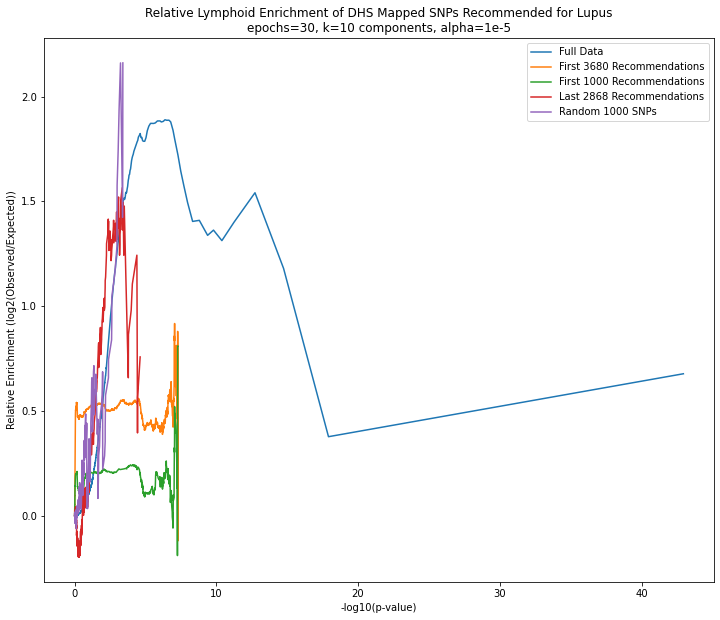

In [46]:
fig = plt.figure(figsize=(12, 10))
fig.patch.set_facecolor('white')


correct_comp_ind = np.where(comps=='Lymphoid')[0][0]
print(correct_comp_ind)
plt.plot(full_pval_mlog[:], full_log_obs_over_exp[correct_comp_ind][:])
plt.plot(recs_pval_mlog, recs_log_obs_over_exp[correct_comp_ind])
plt.plot(recs_first_1000_pval_mlog, recs_first_1000_log_obs_over_exp[correct_comp_ind])
plt.plot(leftover_pval_mlog, leftover_log_obs_over_exp[correct_comp_ind])
plt.plot(random_snps_pval_mlog, random_snps_log_obs_over_exp[correct_comp_ind])


plt.legend(['Full Data', 'First ' + str(len(trait_recs_df)) + ' Recommendations', 'First 1000 Recommendations', 'Last ' + str(len(trait_leftover_snps_df)) + ' Recommendations', 'Random 1000 SNPs'])
plt.xlabel('-log10(p-value)')
plt.ylabel('Relative Enrichment (log2(Observed/Expected))')
plt.title('Relative ' + comps[correct_comp_ind] + ' Enrichment of DHS Mapped SNPs Recommended for Lupus\nepochs=30, k=10 components, alpha=1e-5')

In [78]:
comps[2]
# correct_comp_ind = np.where(comps=='Myeloid / erythroid')[0][0]

'Myeloid / erythroid'

In [83]:
random_snps_log_obs_over_exp[2, -19:]

array([0.17259419,       -inf,       -inf,       -inf,       -inf,
             -inf,       -inf,       -inf,       -inf,       -inf,
             -inf,       -inf,       -inf,       -inf,       -inf,
             -inf,       -inf,       -inf,       -inf])